# Viz 4 — Perturbation Robustness (RQ2)

Two-panel figure for **RQ2: How robust are SparqlCE embeddings to structural perturbations?**

- **Panel A (operational)**: MRR before vs after perturbation per model. Shows that SparqlCE's *perturbed* MRR exceeds every baseline's *original* MRR — the key practical claim.
- **Panel B (granular)**: Mean cosine similarity per perturbation × model. Shows per-operator behaviour, including SparqlCE's mild sensitivity to `filter_true` and `distinct_toggle`.

Inputs:
- `results/robustness/robustness_results.json` — generated by your existing RQ2 evaluation script.

Output:
- `results/robustness_panel_rq2.pdf` — print-ready, embeddable in §5 of the paper.

In [1]:
import json
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---- Project path setup (matches Viz 1 convention) ----
_PROJECT_ROOT = Path.cwd().parents[1]
if str(_PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(_PROJECT_ROOT))

# Academic plotting theme (matches Viz 1)
sns.set_theme(style="ticks", context="paper", font_scale=1.4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print(f"✓ Project root: {_PROJECT_ROOT}")

✓ Project root: /local/upb/users/z/zahera/profiles/unix/cs/SPARQL-Embeddings/notebooks


In [3]:
# ====================================================================
# 1. Load robustness results
# ====================================================================
ROBUSTNESS_PATH = os.path.join(_PROJECT_ROOT, "../results/robustness", "robustness_results.json")

# Safety fallback if pathing configuration differs slightly in this kernel
if not os.path.exists(ROBUSTNESS_PATH):
    ROBUSTNESS_PATH = os.path.join(_PROJECT_ROOT, "datasets", "robustness_results.json")

if not os.path.exists(ROBUSTNESS_PATH):
    raise FileNotFoundError(
        f"Robustness results not found at your configured locations. "
        f"Please verify where robustness_results.json is stored."
    )

with open(ROBUSTNESS_PATH, "r", encoding="utf-8") as f:
    raw = json.load(f)

print(f"✓ Loaded {ROBUSTNESS_PATH}")
print(f"  Top-level model keys in JSON: {list(raw.keys())}")

# Map names to clean display labels for academic printing
MODEL_RENAME = {
    "sparqlce": "SparqlCE", "sparqlCE": "SparqlCE",
    "e5": "E5-base", "e5-base": "E5-base", "e5_base": "E5-base",
    "qwen": "Qwen3", "qwen3": "Qwen3", "qwen3-embedding": "Qwen3",
    "tfidf": "TF-IDF", "tf-idf": "TF-IDF", "tf_idf": "TF-IDF",
}

summary = {}
per_pert = {}

# Explicitly parse based on your exact JSON schema
for m, vals in raw.items():
    if not isinstance(vals, dict):
        continue
        
    # Standardize model name for printing/plots
    m_norm = MODEL_RENAME.get(m.lower(), m)
    
    # 1. Extract Summary statistics using your exact keys
    summary[m_norm] = {
        "mrr_original": vals.get("mrr_original"),
        "mrr_perturbed": vals.get("mrr_perturbed"),
        "cosine_mean": vals.get("overall_mean_cos_sim"),
    }
    
    # 2. Extract per-perturbation breakdown from your "per_type" object
    pp = vals.get("per_type", {})
    if isinstance(pp, dict) and pp:
        per_pert[m_norm] = {}
        for pert_name, pert_metrics in pp.items():
            if isinstance(pert_metrics, dict):
                # Grab the cosine metric inside the nested object
                val = pert_metrics.get("mean_cos_sim")
                if val is not None:
                    per_pert[m_norm][pert_name] = float(val)
            else:
                per_pert[m_norm][pert_name] = float(pert_metrics)

# ====================================================================
# Validation Checks
# ====================================================================
missing_mrr = [m for m, v in summary.items()
               if v["mrr_original"] is None or v["mrr_perturbed"] is None]
if missing_mrr:
    raise KeyError(
        f"MRR fields missing for {missing_mrr}. Check if keys match 'mrr_original' or 'mrr_perturbed'."
    )

if not per_pert:
    raise KeyError(
        "Per-perturbation breakdowns ('per_type') could not be populated. Please check your json file structure."
    )

print("\n✓ Schema Mapping Successful!")
print(f"  Models mapped:        {list(summary.keys())}")
print(f"  Perturbations found: {list(next(iter(per_pert.values())).keys())}")

✓ Loaded /local/upb/users/z/zahera/profiles/unix/cs/SPARQL-Embeddings/notebooks/../results/robustness/robustness_results.json
  Top-level model keys in JSON: ['sparqlce', 'e5', 'qwen', 'tfidf']

✓ Schema Mapping Successful!
  Models mapped:        ['SparqlCE', 'E5-base', 'Qwen3', 'TF-IDF']
  Perturbations found: ['variable_renaming', 'redundant_optional', 'filter_true', 'distinct_toggle', 'triple_shuffle', 'union_duplication', 'subquery_wrapping']


In [4]:
# ====================================================================
# 2. Build tidy DataFrames for plotting
# ====================================================================
MODEL_ORDER = ["SparqlCE", "TF-IDF", "E5-base", "Qwen3"]   # fixed order across panels
MODEL_ORDER = [m for m in MODEL_ORDER if m in summary]

# Long-format MRR DataFrame (Panel A)
mrr_rows = []
for m in MODEL_ORDER:
    mrr_rows.append({"model": m, "condition": "Original",  "MRR": summary[m]["mrr_original"]})
    mrr_rows.append({"model": m, "condition": "Perturbed", "MRR": summary[m]["mrr_perturbed"]})
mrr_df = pd.DataFrame(mrr_rows)

# Long-format per-perturbation DataFrame (Panel B)
PERT_ORDER = [
    "variable_renaming", "triple_shuffle", "redundant_optional",
    "union_duplication", "subquery_wrapping", "filter_true", "distinct_toggle",
]
PERT_LABELS = {
    "variable_renaming":   "var.\nrename",
    "triple_shuffle":      "triple\nshuffle",
    "redundant_optional":  "redund.\nOPTIONAL",
    "union_duplication":   "UNION\ndup.",
    "subquery_wrapping":   "subquery\nwrap",
    "filter_true":         "FILTER\n(true)",
    "distinct_toggle":     "DISTINCT\ntoggle",
}

pp_rows = []
for m in MODEL_ORDER:
    if m not in per_pert:
        continue
    for pname in PERT_ORDER:
        if pname in per_pert[m]:
            pp_rows.append({"model": m, "perturbation": pname, "cosine": per_pert[m][pname]})
pp_df = pd.DataFrame(pp_rows)

print("MRR (Panel A):")
print(mrr_df.pivot(index="model", columns="condition", values="MRR").round(4))
print("\nPer-perturbation cosine (Panel B):")
print(pp_df.pivot(index="perturbation", columns="model", values="cosine").round(4))

MRR (Panel A):
condition  Original  Perturbed
model                         
E5-base      0.2460     0.2336
Qwen3        0.2437     0.2386
SparqlCE     0.5206     0.4986
TF-IDF       0.3517     0.3407

Per-perturbation cosine (Panel B):
model               E5-base   Qwen3  SparqlCE  TF-IDF
perturbation                                         
distinct_toggle      0.9793  0.9887    0.9767  0.9754
filter_true          0.9910  0.9940    0.9825  0.9810
redundant_optional   0.9911  0.9905    1.0000  0.9570
subquery_wrapping    0.9979  0.9887    1.0000  0.9893
triple_shuffle       0.9989  0.9946    0.9999  0.9969
union_duplication    0.9892  0.9722    1.0000  0.9274
variable_renaming    0.9884  0.9592    1.0000  0.9525


✓ Saved robustness panel figure with bottom legends to: /local/upb/users/z/zahera/profiles/unix/cs/SPARQL-Embeddings/notebooks/results/robustness_panel_rq2.pdf


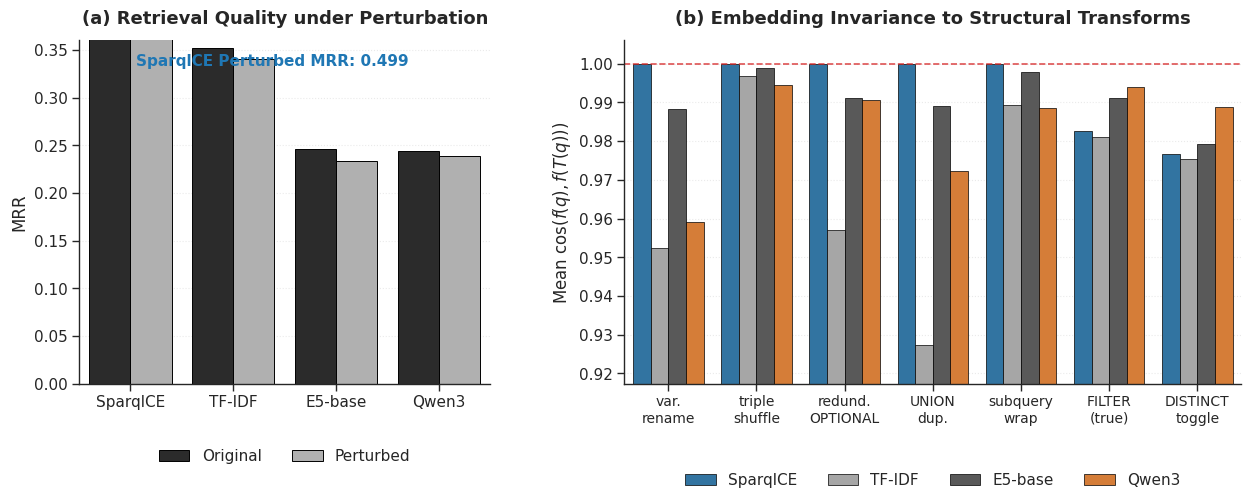

In [8]:
# ====================================================================
# 3. Two-panel figure (Legends Positioned Below Visual Content)
# ====================================================================
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Academic color palette
PALETTE = {
    "SparqlCE":  "#1f77b4",   # Sharp blue (Highlighted model)
    "TF-IDF":    "#a6a6a6",   # Light grey
    "E5-base":   "#595959",   # Mid grey
    "Qwen3":     "#ef7a1e",   # Distinct orange for LLM baseline
}

# Increased height slightly to 5.2 to allow comfortable padding for legends underneath
fig, (axA, axB) = plt.subplots(1, 2, figsize=(15, 5.2),
                               gridspec_kw={"width_ratios": [1.0, 1.5], "wspace": 0.26})

# --------------------------------------------------------------------
# Panel A: MRR before vs after perturbation per model
# --------------------------------------------------------------------
sns.barplot(
    data=mrr_df, x="model", y="MRR", hue="condition",
    order=MODEL_ORDER, hue_order=["Original", "Perturbed"],
    palette={"Original": "#2b2b2b", "Perturbed": "#b0b0b0"},
    ax=axA, edgecolor="black", linewidth=0.7,
)

# Extract precise metrics for line plotting from JSON summary
sparqlce_pert = summary["SparqlCE"]["mrr_perturbed"]

# Render structural reference line behind bars using low zorder
axA.axhline(sparqlce_pert, color=PALETTE["SparqlCE"], linestyle="--",
            linewidth=1.5, alpha=0.9, zorder=1)

# Position annotation text cleanly on the upper left, completely away from any text collisions
axA.text(0.05, 0.33, f"SparqlCE Perturbed MRR: {sparqlce_pert:.3f}",
         ha="left", va="bottom", fontsize=11, color=PALETTE["SparqlCE"],
         fontweight="bold")

axA.set_title("(a) Retrieval Quality under Perturbation", fontsize=13, fontweight="bold", pad=12)
axA.set_xlabel("")
axA.set_ylabel("MRR", fontsize=12, fontweight="medium")
axA.set_ylim(0, 0.36)  
axA.tick_params(labelsize=11)

# MOVE LEGEND A BELOW: Positioned below x-axis labels horizontally
axA.legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.15), 
           ncol=2, frameon=False, fontsize=11)
axA.grid(True, axis="y", linestyle=":", alpha=0.4)

# --------------------------------------------------------------------
# Panel B: per-perturbation mean cosine similarity
# --------------------------------------------------------------------
sns.barplot(
    data=pp_df, x="perturbation", y="cosine", hue="model",
    order=PERT_ORDER, hue_order=MODEL_ORDER,
    palette=[PALETTE[m] for m in MODEL_ORDER],
    ax=axB, edgecolor="black", linewidth=0.5,
)

axB.set_title("(b) Embedding Invariance to Structural Transforms", fontsize=13, fontweight="bold", pad=12)
axB.set_xlabel("")
axB.set_ylabel("Mean $\\cos(f(q), f(T(q)))$", fontsize=12, fontweight="medium")

# Perfect invariance horizontal baseline indicator
axB.axhline(1.0, color="#d62728", linestyle="--", linewidth=1.2, alpha=0.8, zorder=1)

# Dynamic zoom ceiling configuration
y_min = max(0.91, pp_df["cosine"].min() - 0.01)
axB.set_ylim(y_min, 1.006)

# Map human-readable multiline labels cleanly
formatted_labels = [PERT_LABELS[p].replace(" ", "\n") for p in PERT_ORDER]
axB.set_xticks(range(len(PERT_ORDER)))
axB.set_xticklabels(formatted_labels, fontsize=10, fontweight="medium")
axB.tick_params(axis="y", labelsize=11)

# MOVE LEGEND B BELOW: Positioned below x-axis labels horizontally in a single row
axB.legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.22), 
           ncol=4, frameon=False, fontsize=11)
axB.grid(True, axis="y", linestyle=":", alpha=0.4)

# Clean boundary execution frame cleanup
sns.despine(ax=axA)
sns.despine(ax=axB)

# tight_layout handles margins, but we use subplots_adjust to preserve our custom bottom legend space
#plt.tight_layout()
fig.subplots_adjust(bottom=0.22)

# ---- Save Polished File ----
output_pdf = os.path.join(_PROJECT_ROOT, "results", "robustness_panel_rq2.pdf")
os.makedirs(os.path.dirname(output_pdf), exist_ok=True)
plt.savefig(output_pdf, dpi=300, bbox_inches="tight")
print(f"✓ Saved robustness panel figure with bottom legends to: {output_pdf}")
plt.show()

In [6]:
# ====================================================================
# 4. Sanity check: the headline numerical claim for the caption
# ====================================================================
sparqlce_pert = summary["SparqlCE"]["mrr_perturbed"]
baselines_orig = {m: summary[m]["mrr_original"] for m in MODEL_ORDER if m != "SparqlCE"}

print(f"SparqlCE MRR after perturbation: {sparqlce_pert:.4f}")
print(f"Baselines MRR before perturbation:")
for m, v in baselines_orig.items():
    diff = sparqlce_pert - v
    cmp = ">" if diff > 0 else "≤"
    print(f"  {m:10s}: {v:.4f}   (SparqlCE perturbed {cmp} {m} original by {diff:+.4f})")

print()
print("Per-perturbation weakest operator per model (lowest cosine):")
for m in MODEL_ORDER:
    if m in per_pert:
        worst = min(per_pert[m].items(), key=lambda kv: kv[1])
        print(f"  {m:10s}: {worst[0]} ({worst[1]:.4f})")

SparqlCE MRR after perturbation: 0.4986
Baselines MRR before perturbation:
  TF-IDF    : 0.3517   (SparqlCE perturbed > TF-IDF original by +0.1468)
  E5-base   : 0.2460   (SparqlCE perturbed > E5-base original by +0.2525)
  Qwen3     : 0.2437   (SparqlCE perturbed > Qwen3 original by +0.2548)

Per-perturbation weakest operator per model (lowest cosine):
  SparqlCE  : distinct_toggle (0.9767)
  TF-IDF    : union_duplication (0.9274)
  E5-base   : distinct_toggle (0.9793)
  Qwen3     : variable_renaming (0.9592)


## Suggested figure caption (drop into the paper)

> **Figure 4: Robustness of query embeddings to semantics-preserving perturbations (RQ2).**
> *(a)* Retrieval MRR before and after applying perturbations to test queries. Even after perturbation, SparqlCE retrieves more accurately than every baseline does on un-perturbed queries (dashed line). *(b)* Mean cosine similarity between original and perturbed embeddings, broken down by perturbation type. SparqlCE is near-perfectly invariant under five of the seven perturbations; mild sensitivity to `FILTER(true)` and `DISTINCT` toggling is principled, as the `DISTINCT` operator can legitimately change multiset/set semantics. Operators are described in Appendix B.